# Use a learned extraction-time surrogate

**Question:** How does a model-predicted extraction-time ordering produce a feasible plan, and what quantity is actually certified?

**Level:** 1 — Fundamentals

**Prerequisites:** Complete topic 01, CPIT scheduling and bounds.

**Reading time:** 18 minutes

## Objectives

The learned lane predicts expected extraction times so the app can show a plan without first solving the LP relaxation. In this lesson you load the committed model bundle, build one PhaseFlow case, run the learned method and compare its plan with the exact expected-time baseline. You will inspect the model's held-out record and distinguish a fast prediction from a certificate. The expected-time model predicts an ordering feature, not a feasible schedule directly; OreBlocks still constructs the schedule under precedence and capacity rules. A learned bound predictor is also present in the bundle, but its output is an estimate. Certified bounds remain the result of exact relaxation algorithms. This lesson shows one generated core-halo case and does not pretend that one case validates generalization.

## Setup

Install the pinned environment from the repository root with `python -m pip install -r notebooks/requirements.txt`. This lesson uses `oreblocks==0.6.3`. Model files are committed; this notebook does not train or install anything.

```bash
python -m pip install -r notebooks/requirements.txt
```

In [1]:
# Load the pipeline and the committed learned-model bundle.
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
from pipeline.model.learned import LearnedBundle
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.3


## Data

Inputs are generated through PhaseFlow's MIT-licensed instance pipeline. The model bundle is the committed set `models/expected-time.json`, `models/bound.json`, and `models/guard-validation.json`; these are model artifacts from the product's synthetic training study, not observations from a named mine. OreBlocks 0.6.3 supplies the TopoSort schedule and exact expected-time baseline. The learned model was trained with deposits separated by seed: twelve training seeds, six held-out seeds and a third disjoint validation set. These small lesson instances use new declared seeds. Never interpret their scores as replacing the persisted validation report or as evidence about a real block model.

## Method

The expected-time model maps block and scenario features f_b to a normalized time estimate: Ê_b=(T+1)σ(MLP((f_b−μ)/s)). OreBlocks uses that estimate as a TopoSort priority and applies its ordinary feasibility rules. The model accelerates preview by skipping the LP solve; it does not certify objective value or feasibility independently. For comparison, ExTS uses the actual expected extraction times from the LP relaxation. We run both paths on the same case and compute ratio = NPV_learned / NPV_ExTS. A ratio is meaningful only when the denominator is positive and the plans solve the same instance. The prediction, feasibility construction, baseline and score remain separate steps so a user can see what is learned and what is still exact.

Build one small core-halo input. Its shape is used because the persisted study measures concentrated learned-plan failures there; the tiny geometry is a demonstration rather than a validation split.

In [2]:
# Build a seeded core-halo teaching case through PhaseFlow.
case = Case(
    id='learned-core-halo-8x8x4', category='teaching',
    title_en='Core halo surrogate lesson', title_es='Leccion surrogate core halo',
    deposit=DepositSpec(kind='twin', archetype='core_halo', dims=(8, 8, 4), seed=223),
    scenario=Scenario(periods=6, discount_rate=0.10,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract:', instance.report.ok, '| blocks:', instance.n_blocks)

contract: True | blocks: 256


Load committed weights without retraining. The report includes held-out model metrics and a separate guard-validation record. Compare both partitions instead of showing only the number that helped choose the rule.

In [3]:
# Load model artifacts from the repository and inspect the persisted study.
bundle = LearnedBundle.load(Path('../../../models'))
report = bundle.report()
print('held-out expected-time Spearman:', report['expectedTime'].get('holdout_spearman'))
print('clean guard recall:', report['guard'].get('validation_recall'))
print('guard failures:', report['guard'].get('validation_failures'), '/', report['guard'].get('validation_n'))

held-out expected-time Spearman: 0.8070491200859878
clean guard recall: 0.47183098591549294
guard failures: 142 / 432


Predict the bound ratio for this scenario. It is a learned estimate and cannot replace the exact critical-multiplier or joint LP bound.

In [4]:
# Predict a bound ratio; this learned estimate is not a certificate.
bound_ratio = bundle.predict_bound_ratio(instance, case.scenario)
print('predicted bound ratio:', round(bound_ratio, 4))

predicted bound ratio: 0.5243


Run the learned inference path. Its returned note may report an archetype warning from the measured study; the model does not certify its own schedule.

In [5]:
# Predict the learned plan and retain its timing and reliability note.
learned_row = bundle.for_instance(instance)[0]
learned_name, learned_plan, learned_ms, learned_note = learned_row
print(learned_name, '| NPV:', round(learned_plan.npv, 2))
print('advertencia de arquetipo:', bundle.unreliable_here(instance.cpit, instance.archetype) is not None)

learned-expected-time | NPV: 965079.4
advertencia de arquetipo: True


Run exact ExTS and compare objective values on one shared instance. The exact plan is a method baseline, not automatically a globally optimal integer plan. Its relaxation provides the certified bound elsewhere in the product.

In [6]:
# Compute the exact expected-time schedule used as the plan-value baseline.
exts, _ = ob.solve_cpit(instance.cpit, instance.precedence, method='expected', local_search=False)
ratio = learned_plan.npv / exts.npv if exts.npv > 0 else float('nan')
print('ExTS NPV:', round(exts.npv, 2), '| learned / ExTS:', round(ratio, 3))

ExTS NPV: 1126625.71 | learned / ExTS: 0.857


Plot the two computed plan values. No bound is drawn because plan value and certified upper bound are different quantities.

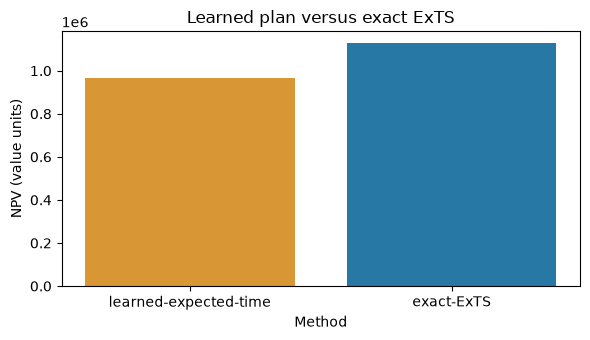

In [7]:
# Compare learned and exact baseline plan values on this single case.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([learned_name, 'exact-ExTS'], [learned_plan.npv, exts.npv], color=['#d99635', '#2878a5'])
ax.set(title='Learned plan versus exact ExTS', xlabel='Method', ylabel='NPV (value units)')
fig.tight_layout()
plt.show()

### Figure 1

The bars compare the actual NPV of the learned and exact expected-time schedules on one identical instance. Their difference is the consequence of the predicted ordering after OreBlocks applies feasibility rules. The dashed? no, the chart has no bound because neither schedule value is a certificate. A closer pair indicates better performance for this case only; it does not measure held-out generalization. The printed ratio below is the corresponding computed statistic. Read the model report separately for its deposit-level held-out results.

## Results

**Answer:** The learned plan scores 965079.40 versus exact ExTS at 1126625.71, a ratio of 0.857. The learned estimate is a fast ordering surrogate, not a certificate; the exact relaxation supplies the bound, and this one core-halo case is a failure-shaped example rather than a generalization study.

In [8]:
# Print the computed answer values.
print(f'learned={learned_plan.npv:.2f}; exact={exts.npv:.2f}; ratio={ratio:.3f}')

learned=965079.40; exact=1126625.71; ratio=0.857


## Summary

You loaded a committed model, ran its inference path, and compared the resulting feasible plan with exact ExTS on one case. The learned model saves the relaxation needed to obtain true extraction-time weights; it does not replace precedence checks, capacity checks or certified upper bounds. Use `report()` to inspect the held-out and guard records, and use per-instance exact comparison when it is available. Treat an archetype warning as evidence from synthetic twins, not a diagnosis of real orebody reliability.

## References

- https://arxiv.org/abs/1412.6980
- https://doi.org/10.1007/s11081-012-9186-2
- PhaseFlow research: `docs/methodologies/07_learned.md` and `docs/methodologies/08_when-the-surrogate-fails.md`.